# Exercise 4: Molecular Dynamics Lennard-Jones simulation
### Exercise 4.1: Velocity distribution histogram
  > **goal**: implement a measure of $p(v, T)$ in the Lennard-Jones simulator, using data blocking to obtain progressive average and error estimates.

A measurable distribution is implemented via a `MeasurableHistogram` class:
```cpp
class MeasurableHistogram {
private:
  std::string _name;
  int _n_bins;
  std::vector<double> _block_sum{}, _block_sum_sq{};
  std::vector<double> _global_av{}, _global_av_sq{};
  /* evaluation methods */
  std::function<std::vector<double>(std::span<const double>)> _compute;
  std::function<double(double, double, int)> _block_estimate;
  /* data streams */
  std::ofstream _output_global_stream;
  std::ofstream _output_blocks_stream;

public:
  MeasurableHistogram(
      std::string, int,
      std::function<std::vector<double>(std::span<const double>)>,
      std::function<double(double, double, int)>);
  MeasurableHistogram(
      std::string, int,
      std::function<std::vector<double>(std::span<const double>)>);
  void measure(std::span<const double>);
  void end_block(int, int);
  void finalize(int);
};
```

of which the `LJSystem` class contains two: $p(v)$ and $g(r)$, as `std::optional<MeasurableHistogram>` objects, constructed after the simulation parameters have been read: in `LJSystem`'s constructor, here's the implementation of the `_pofv` object:
```cpp
LJSystem::LJSystem() : System() {
  read_lj_settings();
  load_init_config();

  ...
  /* other measurable quantities definitions */
  ...

  _pofv.emplace("pofv", _n_bins_pofv, [this](std::span<const double> speeds) {
    std::vector<double> hist(_n_bins_pofv, 0.0);
    for (double v : speeds) {
      int bin = static_cast<int>(v / _bin_size_pofv);
      if (bin >= 0 && bin < _n_bins_pofv) {
        hist[bin] += 1.0 / (_npart * _bin_size_pofv);
      }
    }
    return hist;
  });
}
```

This sets the distribution's name (useful for naming its output files) and, according to `_n_bins_pofv` read within `read_lj_settings()`, uses a *lambda* to set how each bin is to be filled when measuring.

In the simulation loop we have a call to `LJSystem`'s `measure()` function after each step and a call to `end_block(int)` after each block:
```cpp
int main() {
  ...
  /* initialization and thermalization */
  ...

  for (int block = 0; block < nblocks; block++) {
    for (int step = 0; step < nsteps; step++) {
      sys.step();
      sys.measure();
    }
    sys.end_block(block);
  }

  ...
  /* clean up */
  ...

  return 0;
}
```

`void LJSystem::measure()` takes istantaneous measures of
  - potential energy per particle $u$
  - kinetic energy per particle $k$
  - virial
  - a `distances` array that accumulates all distances between pairs of particles
  - a`speeds` array which accumulates all particles' speeds
  
then passes them to all measurable quantities defined in `LJSystem`'s constructor, included `_pofv` and `_gofr` through their `measure(std::span<const double>)` methods:
```cpp
void LJSystem::measure() {
  double k = 0.0, u = 0.0, virial = 0.0;
  std::vector<double> distances, speeds;

  for (int i = 0; i < _npart; i++) {
    double v = mod(_particles(i).get_v());
    speeds.emplace_back(v);
    k += 0.5 * _m * v * v;

    for (int j = i + 1; j < _npart; j++) {
      double r =
          _nearest_image_dist(_particles(i).get_x(), _particles(j).get_x());
      distances.emplace_back(r);
      if (r < _r_cut) {
        double sr6 = std::pow(_sigma / r, 6.0);
        double sr12 = sr6 * sr6;
        u += 4.0 * _epsilon * (sr12 - sr6);
        virial += 4.0 * _epsilon * (sr12 - 0.5 * sr6);
      }
    }
  }

  k /= _npart;
  u = u / _npart + _vtail;

  std::array<double, 3> args{k, u, virial};
  for (auto &measurable : _measurables) {
    measurable.measure(args);
  }
  _gofr->measure(distances);
  _pofv->measure(speeds);
}
```

The `MeasurableHistogram::measure` method uses the `MeasurableHistogram::_compute` method (the one set with a *lambda* in the object's definition) to fill a histogram with the data given, then accumulates
  - the histogram values in `_block_sum`
  - the histogram's squared values in `_block_sum_sq` (*useful if we are measuring a variance, which is not the case for $p(v)$*)
  
  ```cpp
void MeasurableHistogram::measure(std::span<const double> args) {
  std::vector<double> hist = _compute(args);
  for (int bin = 0; bin < _n_bins; bin++) {
    _block_sum[bin] += hist[bin];
    _block_sum_sq[bin] += hist[bin] * hist[bin];
  }
}
```

At the end of each block, the simulation loop calls `LJSystem`'s `end_block(int)` method.
This uses the accumulated values in `_block_sum` and in`_block_sum_sq` to compute the block's estimate for our histogram (using the `_block_estimate` method), then
  - accumulates the block estimate in `_global_av`, an array that will contain the average of all blocks estimates
  - accumulates the block estimate *squared* in `_global_av_sq`, used to compute the error on each bin
  - writes the block estimate values as a new line in the "output/<_name>_blocks.csv" file
  - resets all `_block_sum` and `_block_sum_sq` values to 0.0

```cpp
void MeasurableHistogram::end_block(int block_number, int n_samples) {
  _output_blocks_stream << block_number + 1 << ",";
  for (int bin = 0; bin < _n_bins; bin++) {
    double bin_block_estimate =
        _block_estimate(_block_sum[bin], _block_sum_sq[bin], n_samples);
    _global_av[bin] += bin_block_estimate;
    _global_av_sq[bin] += bin_block_estimate * bin_block_estimate;

    if (bin < _n_bins - 1) {
      _output_blocks_stream << bin_block_estimate << ",";
    } else {
      _output_blocks_stream << bin_block_estimate << std::endl;
    }

    _block_sum[bin] = 0;
    _block_sum_sq[bin] = 0;
  }
}
```

Lastly, when the simulation loop has finished, `MeasurableHistogram::finalize(int)` is called, which writes in the "output/<_name>_global.csv" file the final global average of each bin, along with its estimate for the error:

```cpp
void MeasurableHistogram::finalize(int n_blocks) {
  for (int bin = 0; bin < _n_bins; bin++) {
    double bin_global_av = _global_av[bin] / n_blocks;
    double err = error(_global_av[bin], _global_av_sq[bin], n_blocks);
    _output_global_stream << bin_global_av << "," << err << std::endl;
  }
}
```

### Exercise 4.2: Convergence to Maxwell-Boltzmann
  > **goal**: perform a MD simulation for a LJ gas starting from a low-entropy state, then verify and show that its $p(v, T)$ converges to a Maxwell-Boltzmann distribution.
>
> Use:
> $$ \rho^* = 0.05 \quad\text{and}\quad T^* = 2.0 $$
> and start with
>   - particles in a ***FCC*** crystal occupying half box width in each dimension
>   - velocities distributed as $p_\delta(v) = \delta(v - v_T)$, each along a random axis

This is the function (called within `LJSystem`'s constructor) that generates a low-entropy initial state:
  1. particles occupy an ***FCC*** lattice spanning $[-L/2, 0)$ along each axis (*this works if the particle number is exatly $4 \cdot n^3$ for come $n$, and we will run the simulation witn $N = 108 = 4 \cdot 3^3$)
  2. velocities are first set assigning $v_i = \pm v_{T} = \pm \sqrt{3T / m}$ along a random axis (*$v_T$ was decided according the equipartition theorem, even though this is a non-equilibrium state*)
  3. since this method could result in a non-zero overall drift, we subtract the average velocity from all particles
  4. this correction might have influenced the initial system's kinetic energy, so we rescale all velocities by a factor $\sqrt{3T / m\langle v^2\rangle}$
  5. lastly we set `x_old` and `a` for each particle to kickstart the simulation loop

  ```cpp
  void LJSystem::_load_init_config() {
  _particles.set_size(_npart);

  if (!_restarted) { /* not a continuation of
                      * a previous simulation */
    if (_ndim != 3) {
      throw std::runtime_error("FCC lattice is only defined for _ndim = 3.");
    }
    int ncells = static_cast<int>(std::round(std::cbrt(_npart / 4.0)));
    if (4 * ncells * ncells * ncells != _npart) {
      throw std::runtime_error(
          "FCC lattice requires NPART = 4 n^3 (32, 108, 256, 500, ...).");
    }

    double box_fill_perc = 0.5;
    const double a = box_fill_perc * _box_dim / ncells;
    const double basis[4][3] = {
        {0.0, 0.0, 0.0}, {0.5, 0.5, 0.0}, {0.5, 0.0, 0.5}, {0.0, 0.5, 0.5}};

    std::vector<arma::vec> sites;
    sites.reserve(_npart);
    for (int ix = 0; ix < ncells; ix++) {
      for (int iy = 0; iy < ncells; iy++) {
        for (int iz = 0; iz < ncells; iz++) {
          for (const auto &b : basis) {
            arma::vec pos = {(ix + b[0]) * a - _box_dim / 2.0,
                             (iy + b[1]) * a - _box_dim / 2.0,
                             (iz + b[2]) * a - _box_dim / 2.0};
            sites.push_back(pos);
          }
        }
      }
    } /* FCC lattice created */

    double v_T = std::sqrt(_ndim * _temp / _m);
    arma::vec v_av(_ndim, arma::fill::zeros);

    std::size_t i = 0;
    for (auto &p : _particles) {
      p.set_x(sites[i++]);

      /* speed is v_T, along a random axis */
      arma::vec v(_ndim, arma::fill::zeros);
      int rand = int(_rng.rannyu() * 6.0);
      v(rand / 2) = (rand % 2 - 0.5) * 2.0 * v_T;
      p.set_v(v);
      v_av += v;
    }

    v_av /= _npart;
    double v_av2 = 0.0;
    for (auto &p : _particles) {
      p.set_v(p.get_v() - v_av);
      for (double v_component : p.get_v()) {
        v_av2 += v_component * v_component;
      }
    }
    v_av2 /= _npart;

    double v_factor = std::sqrt(_ndim * _temp / (v_av2 * _m));
    for (auto &p : _particles) {
      p.set_v(p.get_v() * v_factor);
    }
  } else {
    /* read last state of previous run
     * from a file */
  }

  for (int i = 0; i < _npart; i++) {
    arma::vec x_old = _particles(i).get_x() - _dt * _particles(i).get_v();
    _particles(i).set_x_old(x_old);

    arma::vec a = _force(i) / _m;
    _particles(i).set_a(a);
  }
}

```

This simulattion was run for
  - blocks of $50$ steps each (*they will not be independent, but they will show the system' evolution towards equilibrium*)
  - no equilibration blocks, the goal is to actually see the system thermalizing
  - $100$ simulation (*measured*) blocks, to track the system's time evolution more accurately

with a timestep $\mathrm{d}t = 10^{-3}$ and $r_{cut} = 5.0$. 
All physical parameters were as assigned:
  - $T = 2.0$ (*only used to determine the initial velocity, then the system will settle into a different equilibrium temperature*)
  - $N_{part} = 108$
  - $\rho = 0.05$
  - $\sigma = 1.0$ and $\epsilon = 1.0$

First we load the simulation's data: multiple histograms for $p(v)$ and average kinetic energies for each block

In [15]:
import numpy as np
from pathlib import Path

results_directory = "sim_results/lj_thermalizing/fw_5000" 

logfile_path = Path(results_directory) / "logfile.log"

with open(logfile_path, 'r') as logfile:
  lines = [l for l in logfile if 'N_BINS_POFV:' in l]
  n_bins = int(lines[0].split()[1])

kinetic_file_path = Path(results_directory) / "kinetic_energy_per_particle.csv"

kinetic_data = np.loadtxt(kinetic_file_path, delimiter=',', skiprows=1)
kinetic_blocks = kinetic_data[:,0] + 1
temp_eff_values = 2 * kinetic_data[:,1] / 3.0
temp_eff_error = 2 * kinetic_data[:,2] / 3.0

T = temp_eff_values[-1]

energy_file_path = Path(results_directory) / "energy_per_particle.csv"

energy_data = np.loadtxt(energy_file_path, delimiter=',', skiprows=1)
energy_blocks = energy_data[:,0] + 1
energy_values = energy_data[:,1]
energy_error = energy_data[:,2]

pofv_file_path = Path(results_directory) / "pofv_blocks.csv"

pofv_blocks = np.loadtxt(pofv_file_path, delimiter=',', skiprows=1)[:, 1:]

Then we plot:
  - $p(v)$ for each block are plotted on the same graph as thin lines with a color grading
  - the Maxwell-Boltzmann theoretical expectation is computed using $T = \frac{2}{3} (K / N)$ from the last-measured (*last block, not a block average*) kinetic energy

Text(0, 0.5, '$K + U$')

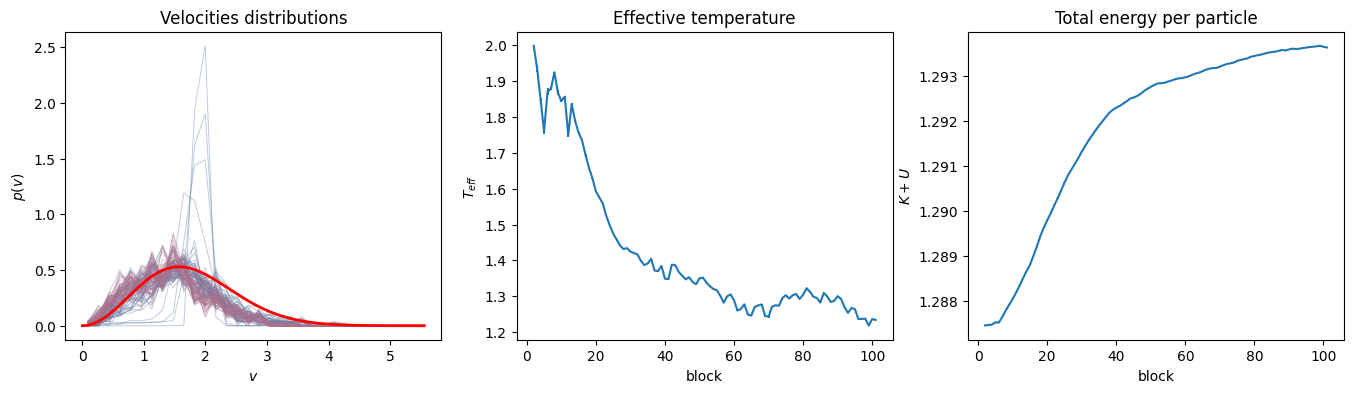

In [16]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

vmin = 0.0
vmax = 5.0 *  np.sqrt(T)
bin_half_width = (vmax - vmin) / (2 * n_bins)
bin_centers = np.linspace(vmin + bin_half_width, vmax - bin_half_width, n_bins)

def maxwell_boltzmann(v, T):
  return 4 * np.pi * v * v * np.exp(- v * v / (2* T)) / ((2 * np.pi * T) ** 1.5)

v_fine = np.linspace(vmin, vmax, n_bins * 100)
pofv_theor = maxwell_boltzmann(v_fine, T)

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(5.5*3, 4*1))

cmap = LinearSegmentedColormap.from_list("thermalizing", ["#5D7EA8", "#B4708A"])
for i, row in enumerate(pofv_blocks):
    axs[0].plot(bin_centers, row, color=cmap(i / (len(pofv_blocks)-1)), alpha=0.4, lw=0.7)
axs[0].plot(v_fine, pofv_theor, color='r', lw=2, linestyle='-', label='Maxwell-Boltzmann distribution (at equilibrium)')
axs[0].set_title("Velocities distributions")
axs[0].set_xlabel("$v$")
axs[0].set_ylabel("$p(v)$")

axs[1].errorbar(kinetic_blocks, temp_eff_values, yerr=temp_eff_error)
axs[1].set_title("Effective temperature")
axs[1].set_xlabel("block")
axs[1].set_ylabel("$T_{eff}$")

axs[2].errorbar(energy_blocks, energy_values, yerr=energy_error)
axs[2].set_title("Total energy per particle")
axs[2].set_xlabel("block")
axs[2].set_ylabel("$K + U$")

As we can see, the first set of blocks are spent moving towards an equilibrium configuration.
Then, after about 40 blocks ($\sim 2000$ steps) the system settles closer to an equilibrium configuration for velocities (a bell curve close to *Maxwell-Boltzmann*) and a more stable temperature value (around $1.2-1.3\,K$).

The total energy per particle remains very close to constant as expected from a MD simulation; its (*small*, about $0.4\%$) variation could be attributed to an unusual initial configuration which would have required a smaller timestep to be rendered more accurately.

### Exercise 4.3: Reversability of solutions
  > **goal**: perform two simulations (with $N_{steps} = 5\cdot10^3$ and $5\cdot10^4$), then start from their final states and perform them in reverse.
  >   Plot the time evolution of their potential energy (forward and backward) and comment.

At the end of every simulation, the positions and velocities for each particle are logged in a dedicated *'output/last_config.log'* file, calling the function
```cpp
void LJSystem::_log_last_config() const {
  std::ofstream last_config_stream("output/last_config.log");
  if (!last_config_stream) {
    std::cerr << "WARNING: Unable to log last configuration in "
                 "\'output/last_config.log\' file."
              << std::endl;
  }

  for (auto p : _particles) {
    for (int i = 0; i < _ndim; i++) {
      last_config_stream << std::to_string(p.get_x()(i)) << " ";
    }
    for (int i = 0; i < _ndim; i++) {
      last_config_stream << std::to_string(p.get_v()(i)) << " ";
    }
    last_config_stream << std::endl;
  }
}
```

of which `IsingSystem` also has its own version.

Then, if the `_restarted` parameter has been set to `true`, the next simulation run will read these data *instead of equilibrating* the system:
```cpp
void LJSystem::_load_init_config() {
  _particles.set_size(_npart);

  if (!_restarted) {
    /* generate initial FCC lattice */
  } else {
    std::ifstream init_config_stream("output/last_config.log");
    if (!init_config_stream) {
      throw std::runtime_error(
          "Unable to open or find \'output/last_config.log\' file.");
    }

    std::string line;
    for (auto &p : _particles) {
      std::getline(init_config_stream, line);
      std::stringstream line_stream(line);

      arma::vec x(_ndim), v(_ndim);
      for (int i = 0; i < _ndim; i++) {
        line_stream >> x(i);
      }
      for (int i = 0; i < _ndim; i++) {
        line_stream >> v(i);
      }

      p.set_x(x);
      p.set_v(v);
    }
  }

  for (int i = 0; i < _npart; i++) {
    arma::vec x_old = _particles(i).get_x() - _dt * _particles(i).get_v();
    _particles(i).set_x_old(x_old);

    arma::vec a = _force(i) / _m;
    _particles(i).set_a(a);
  }
}

```

We can now plot the results: first we define useful functions for loading forward and backward runs and then chaining them into a single run, then we load the data and plot $\frac{U}{N}(t)$ and $T_{eff}(t)$:

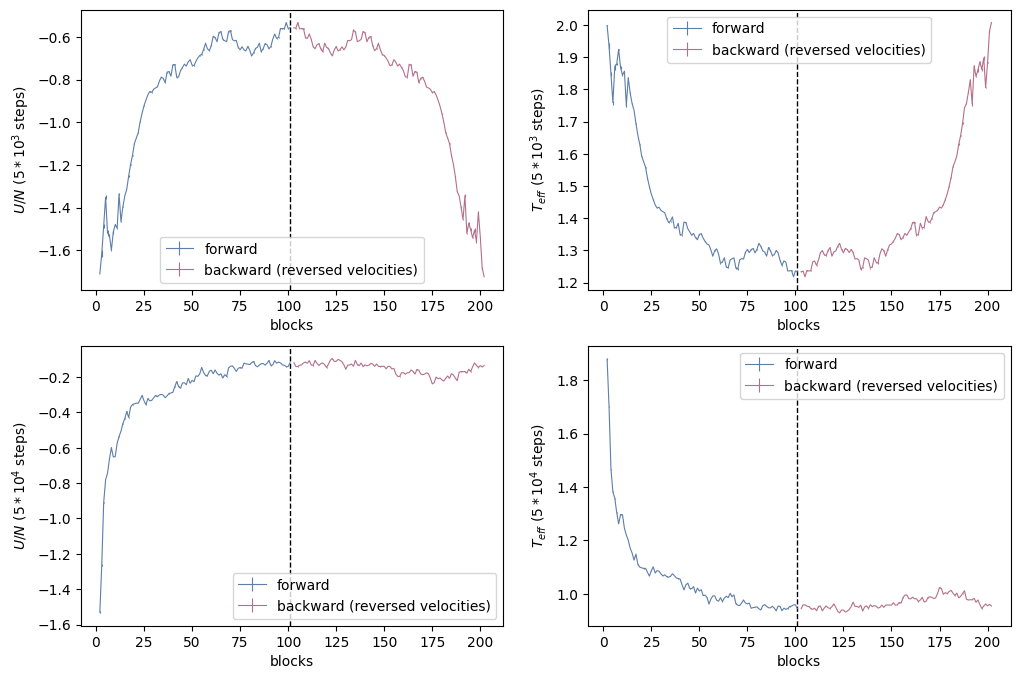

In [18]:
from pathlib import Path

def load_run(results_directory):
  kinetic_data = np.loadtxt(results_directory / "kinetic_energy_per_particle.csv",
                             delimiter=',', skiprows=1)
  pot_energy_data = np.loadtxt(results_directory / "potential_energy_per_particle.csv",
                            delimiter=',', skiprows=1)
  
  blocks = kinetic_data[:, 0] + 1
  temp_eff = 2 * kinetic_data[:, 1] / 3.0
  temp_eff_err = 2 * kinetic_data[:, 2] / 3.0
  pot_energy = pot_energy_data[:, 1]
  pot_energy_err = pot_energy_data[:, 2]

  return blocks, temp_eff, temp_eff_err, pot_energy, pot_energy_err

def combine_fwbw(fw_dir, bw_dir):
    fw_blocks, fw_T, fw_T_err, fw_E, fw_E_err = load_run(fw_dir)
    bw_blocks, bw_T, bw_T_err, bw_E, bw_E_err = load_run(bw_dir)

    n_fwd_blocks = fw_blocks[-1]
    bw_blocks_shifted = bw_blocks + n_fwd_blocks  # continue x-axis past the inversion point

    blocks = np.concatenate([fw_blocks, bw_blocks_shifted])
    temp_eff = np.concatenate([fw_T, bw_T])
    temp_eff_err = np.concatenate([fw_T_err, bw_T_err])
    energy = np.concatenate([fw_E, bw_E])
    energy_err = np.concatenate([fw_E_err, bw_E_err])

    return blocks, temp_eff, temp_eff_err, energy, energy_err, n_fwd_blocks

def plot_fwbw(ax, blocks, values, errors, n_fwd_blocks, ylabel):
    forward_mask = blocks <= n_fwd_blocks
    backward_mask = blocks > n_fwd_blocks

    ax.errorbar(blocks[forward_mask], values[forward_mask], yerr=errors[forward_mask],
                color='#5D7EA8', lw=0.8, label='forward')
    ax.errorbar(blocks[backward_mask], values[backward_mask], yerr=errors[backward_mask],
                color='#B4708A', lw=0.8, label='backward (reversed velocities)')

    ax.axvline(n_fwd_blocks, color='k', linestyle='--', lw=1)
    ax.set_xlabel("blocks")
    ax.set_ylabel(ylabel)
    ax.legend()

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
results_dir = Path("sim_results/lj_thermalizing")
runs = [
  (results_dir / "fw_5000", results_dir / "bw_5000", "$5*10^3$ steps"),
  (results_dir / "fw_50000", results_dir / "bw_50000", "$5*10^4$ steps")
]

for row, (fw_dir, bw_dir, label) in enumerate(runs):
  blocks, temp_eff, temp_eff_err, pot_energy, pot_energy_err, n_fwd_blocks = combine_fwbw(fw_dir, bw_dir)
  plot_fwbw(axs[row, 0], blocks, pot_energy, pot_energy_err, n_fwd_blocks, ylabel=f"$U/N$ ({label})")
  plot_fwbw(axs[row, 1], blocks, temp_eff, temp_eff_err, n_fwd_blocks, ylabel=f"$T_{{eff}}$ ({label})")

From this plots we can see that, in the first simulation (*$100$ blocks with $50$ steps each, as in ex.4.2*), the simulation is accurate enough to return back to the *low-entropy* initial configuration, as we can see both from the potential energy plot and the effective temperature one.

For the second simulation (*$100$ blocks with $500$ steps each*), the system evolves for a total time $10$ times longer and the simulation's accumulated inaccuracies get large enough that the system is unable to go back to the exact configuration it started from.

Note that in this second case, for a short time after time reversal (a time comparable or larger to the $5000$ steps of the first case) the system retraces the last part of its forward simulation, only to then deviate from it and remain in a high-entropy equilibrium state.